In [2]:
import math
pi = math.pi
import matplotlib.pyplot as plt
import numpy as np
import sys
# Suppress warnings
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
import matplotlib
# Integration
import scipy.integrate as integrate
from matplotlib.ticker import LogLocator

In [3]:
matplotlib.rcParams.update({'text.usetex': True})
plt.rcParams.update({
       "text.usetex": True,
       "font.family": "serif",
       "font.size": 16,
       "axes.labelsize": 16,
       "axes.titlesize": 16,
       "legend.fontsize": 14,
       "xtick.labelsize": 14,
       "ytick.labelsize": 14,
})

### Quantum Dots' Parametrs

$ɛ = 1$ On-site mean local energy

$ɛ_L = ɛ + \frac{1}{2}δ$ On-site mean left energy

$ɛ_R = ɛ - \frac{1}{2}δ$ On-site mean right energy

$δ \in [0, 1]$ detuning

$g = 0.01$ coupling strength

$Δ=\sqrt{δ^2+g^2}$

$\Gamma = 0.02 \Delta$ coupling to the reservoirs (the overall frequency scale of the dissipative dynamics)

$Ω=10$ Intra-reservoir tunnelling energy/hopping amplitude

In [4]:
# Quantum Dots' Parametrs
eps = 1.0 # on-site mean local energy
delta = np.linspace(0, 1.0,501) #detuning
eps_L = eps + 0.5 * delta
eps_R = eps - 0.5 * delta
g = 0.01  # coupling strength
Delta  = np.sqrt(delta**2 + g**2)
Gamma = 0.02 * Delta # the overall frequency scale of the dissipative dynamics
Omega = 10.0 # intra-reservoir tunnelling energy/hopping amplitude

### Basis Energies

$E_1 = ɛ+ \frac{Δ}{2}$

$E_1 = ɛ- \frac{Δ}{2}$

In [5]:
# Basis Energies
E1 = eps + 0.5*Delta
E2 = eps - 0.5*Delta

### Reservoirs' parameters


$T=0.3 \varepsilon$

$\mu_L = \varepsilon_L+\varepsilon_R$ Electrochemical potential of the left reservoir

$\mu_R = 0.0$ Electrochemical potential of the right reservoir


In [6]:
# Reservoirs' parameters
T = 0.3 * eps
muL = eps_R+eps_L + np.zeros_like(Delta) # chemical potential of the left reservoir
muR = np.zeros_like(Delta)

### Fermi-Dirac fucntion

\begin{equation*}
f(\omega) = \frac{1}{e^{β(\omega-\mu)}+1}
\end{equation*}


In [7]:
# Dimensionless Fermi-Dirac fucntion expressed with reduced variable x=beta*(E-mu)
f = lambda x: 1./(1. + np.exp(x))

### Spectral density

\begin{align*}
\mathcal{J}_N(\omega) = \frac{\Gamma}{2\pi} \sqrt{1 - \frac{\omega^2}{\Omega^2}} \, \Theta(\Omega - |\omega|)
\end{align*}
### Propability Destribution of Excitation Energy

\begin{align*}
\varphi_j(\omega)=\frac{1}{1-\Gamma / \Omega} \frac{\mathcal{J}_{\mathrm{N}}(\omega)}{\left(\omega-E_j^{\prime}\right)^2+\Gamma_j^2 / 4}
\end{align*}
### Shifted Energies and Decay Rates

\begin{align*}
E'_j = \frac{1 - \Gamma / 2\Omega}{1 - \Gamma / \Omega} E_j, \quad
\Gamma_j = \frac{\sqrt{1 - \Gamma / \Omega - E_j^2 / \Omega^2}}{1 - \Gamma / \Omega} \Gamma.
\end{align*}
### Transmission function

\begin{align*}
\mathcal{T}(\omega)=\frac{\pi g^2}{2} \varphi_1(\omega) \varphi_2(\omega)
\end{align*}

### Uder Exponential-propagator approximation (EPA)

\begin{align*}
E'_j \approx E_j, \quad
\Gamma_j = \frac{\sqrt{1 - \Gamma / \Omega - E_j^2 / \Omega^2}}{1 - \Gamma / \Omega} \Gamma  \approx 2 \pi \mathcal{J}_N(E_j).
\end{align*}

In [8]:
# Spectral density
def J(omega, Gamma, Omega):
     return Gamma/(2.0*np.pi)*np.sqrt(1.0-omega**2/Omega**2)*np.heaviside(Omega-abs(omega),0)
#  Probability distribution of excitation energy
def phi(omega, Gamma, Omega, E):
    E_dash = E
    Gamma_dash = 2.0*np.pi*J(E_dash, Gamma, Omega)
    return 1.0/((omega-E_dash)**2+(Gamma_dash/2.0)**2)*J(omega, Gamma, Omega)
# Trasnmission function
def Tau(omega, Gamma, Omega, E1, E2, g):
    return np.pi*g**2/2.0*phi(omega, Gamma, Omega, E1)*phi(omega, Gamma, Omega, E2)
# Gamma j
Gamma_function = lambda Gamma, Omega, E: (2.0*np.pi*J(E, Gamma, Omega))
# Current
def dI(omega, Gamma, Omega, E1, E2, g, T, muL, muR):
     return Tau(omega, Gamma, Omega, E1, E2, g)*(f((omega-muL)/T)-f((omega-muR)/T))
#Noise
def dS(omega, Gamma, Omega, E1, E2, g, T, muL, muR):
     return Tau(omega, Gamma, Omega, E1, E2, g)*(f((omega-muL)/T)+f((omega-muR)/T)-2.0*f((omega-muL)/T)*f((omega-muR)/T)-Tau(omega, Gamma, Omega, E1, E2, g)*(f((omega-muL)/T)-f((omega-muR)/T))**2)

### Average Steady-State Current

\begin{equation*}
    J_L = \int_{-\infty}^{\infty}  \mathcal{T}(\omega)[f_L(\omega)-f_R(\omega)] d\omega
\end{equation*}

In [9]:
# Integration: <J>
I_avg = np.zeros(np.size(Delta)) #
for i in range(np.size(Delta)): #
  I_avg[i] = integrate.quad(dI,-Omega,Omega,args=(Gamma[i], Omega, E1[i], E2[i], g, T, muL[i], muR[i]), points = [E1[i], E2[i]], epsabs=1.49e-8,epsrel=1.49e-12)[0]

### Current Fluctuations

\begin{equation*}
    D_L = \int_{-\infty}^{\infty}  \mathcal{T}(\omega) \{ [f_L(\omega)+f_R(\omega)-2f_L(\omega)f_R(\omega)]-\mathcal{T}(\omega)[f_L(\omega)-f_R(\omega)]^2\}
    d\omega
\end{equation*}

In [10]:
# Integration: <<J^2>>
I_I = np.zeros(np.size(Delta))
for i in range(np.size(Delta)): #
   I_I[i] = integrate.quad(dS,-Omega,Omega,args=(Gamma[i], Omega, E1[i], E2[i], g, T, muL[i], muR[i]), points = [E1[i], E2[i]], epsabs=1.49e-8,epsrel=1.49e-12)[0]

### Master Eqaution

In [11]:
#Functions for Current, Flcutuations
def Vectorize_Mat (M):
    return Qobj(np.concatenate([M[:, i:i+1] for i in range(M.shape[1])], axis=0))
##Inputs: LList: list of jump operators; NuList: list of jump coefficients (e.g. +1 and -1 for particle current jumps)
def JJ(LList, NuList):
    result = Qobj(np.zeros(tensor([LList[0].conj(), LList[0]]).shape))
    for i in range(len(NuList)):
        result +=  NuList[i]*Qobj(tensor([LList[i].conj(), LList[i]]),dims=tensor([LList[0].conj(), LList[0]]).shape)
    return result
##Inputs: sst: steady state as qutip object; JJj: Jump operators from above
def Current(sst,JJj):
    N_sst=sst.shape[0]
    id = Vectorize_Mat(qeye(N_sst))
    return(np.real(id.dag()*JJj*Vectorize_Mat(sst)))
##Inputs: Lbb: Lindbladian in qutip format; steadys: steady state in qutip format
# JJ2: the jump operator with all elements in NuList equal to 1; JJ: the jump operator
def Noise(Lbb, steadys, JJ2, JJ):
    N_sst=steadys.shape[0]
    vectsteady=Vectorize_Mat(steadys)
    I2L = Vectorize_Mat(qeye(N_sst)).dag()
    # Calculate the expression using NumPy operations
    alpha=JJ*vectsteady
    A=np.vstack((Lbb.full(),I2L.full()))
    B=np.vstack(((alpha - vectsteady*I2L*alpha).full(),0))
    z= Qobj(np.linalg.lstsq(A,B,rcond=None)[0])
    K=I2L*JJ2*vectsteady
    result = K-2*I2L*JJ*z
    return np.real(result)

In [12]:
from qutip import *
# Creation and annihilation operators for N quantum dots: Define operators for each quantum dot
N = 2
def fermion_annihilation(N, i):
    """
    Fermionic annihilation operator at site i using Jordan-Wigner transformation.

    Parameters:
    - N: total number of sites
    - i: site index (0-based)

    Returns:
    - Qobj: fermionic annihilation operator c_i
    """
    if not (0 <= i < N):
        raise ValueError("Index i must be between 0 and N-1")

    op_list = [sigmaz() for _ in range(i)]          # σ_z^⊗i
    op_list.append(sigmam())                        # σ_-
    op_list.extend([qeye(2) for _ in range(N - i - 1)])  # I^⊗(N-i-1)

    return tensor(op_list)

c0 = fermion_annihilation(N, 0)
c1 = fermion_annihilation(N, 1)

### Non-additivity in the local basis

### Orthogonal Rotation Matrix

\begin{equation*}
R = \frac{1}{\sqrt{2\Delta}}
\left(
\begin{array}{cc}
\sqrt{\Delta + \delta} & -\sqrt{\Delta - \delta} \\ \sqrt{\Delta - \delta} & \sqrt{\Delta + \delta}
\end{array}
\right)
\end{equation*}

In [13]:
# Orthogonal rotation matrix
R = 1.0/np.sqrt(2*Delta) * np.array([[np.sqrt(Delta+delta), -np.sqrt(Delta-delta)],[np.sqrt(Delta-delta), np.sqrt(Delta+delta)]])

### Decay Rates

\begin{align*}
\Gamma_j = \frac{\sqrt{1 - \Gamma / \Omega - E_j^2 / \Omega^2}}{1 - \Gamma / \Omega} \Gamma \approx 2 \pi \mathcal{J}_N(E_j)
\end{align*}

### Gammas
$ \Gamma_{L,j}= \Gamma_{j}R_{1j}^2$

$ \Gamma_{R,j}= \Gamma_{j}R_{2j}^2$

$j=1,2$

In [14]:
# Gamma_L,1
GammaL1 = Gamma_function(Gamma, Omega, E1) * R[0,0]**2
# Gamma_L,2
GammaL2 = Gamma_function(Gamma, Omega, E2) * R[0,1]**2
# Gamma_R,1
GammaR1 = Gamma_function(Gamma, Omega, E1) * R[1,0]**2
# Gamma_R,1
GammaR2 = Gamma_function(Gamma, Omega, E2) * R[1,1]**2

In [15]:
# Decay and gain rates
def dg_m(omega, Gamma, Omega, E, mu, T):
  return phi(omega, Gamma, Omega, E) * (1.0 - f((omega-mu)/T))
def dg_p(omega, Gamma, Omega, E, mu, T):
  return phi(omega, Gamma, Omega, E) * f((omega-mu)/T)

### Deacay and Gian Rates

\begin{align*}
\gamma_{\alpha, j}^{-}=\Gamma_{\alpha, j} \int \mathrm{~d} \omega \ \varphi_j(\omega)[1-f_{α}(ω)] \\
\gamma_{\alpha, j}^{+}=\Gamma_{\alpha, j} \int \mathrm{~d} \omega \ \varphi_j(\omega)f_{α}(ω) \\
\end{align*}




In [16]:
# Decay and gain rates
gammaL1_m, gammaR1_m, gammaL2_m, gammaR2_m = np.zeros(np.size(Delta)), np.zeros(np.size(Delta)), np.zeros(np.size(Delta)),np.zeros(np.size(Delta))
gammaL1_p, gammaR1_p, gammaL2_p, gammaR2_p = np.zeros(np.size(Delta)), np.zeros(np.size(Delta)), np.zeros(np.size(Delta)),np.zeros(np.size(Delta))
for i in range(np.size(Delta)): #
  gammaL1_m[i] = integrate.quad(dg_m,-Omega,Omega,args=(Gamma[i], Omega, E1[i], muL[i], T), points = [E1[i]], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaR1_m[i] = integrate.quad(dg_m,-Omega,Omega,args=(Gamma[i], Omega, E1[i], muR[i], T), points = [E1[i]], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaL2_m[i] = integrate.quad(dg_m,-Omega,Omega,args=(Gamma[i], Omega, E2[i], muL[i], T), points = [E2[i]], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaR2_m[i] = integrate.quad(dg_m,-Omega,Omega,args=(Gamma[i], Omega, E2[i], muR[i], T), points = [E2[i]], epsabs=1.49e-8,epsrel=1.49e-12)[0]

  gammaL1_p[i] = integrate.quad(dg_p,-Omega,Omega,args=(Gamma[i], Omega, E1[i], muL[i], T), points = [E1[i]], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaR1_p[i] = integrate.quad(dg_p,-Omega,Omega,args=(Gamma[i], Omega, E1[i], muR[i], T), points = [E1[i]], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaL2_p[i] = integrate.quad(dg_p,-Omega,Omega,args=(Gamma[i], Omega, E2[i], muL[i], T), points = [E2[i]], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaR2_p[i] = integrate.quad(dg_p,-Omega,Omega,args=(Gamma[i], Omega, E2[i], muR[i], T), points = [E2[i]], epsabs=1.49e-8,epsrel=1.49e-12)[0]

In [17]:
gammaL1_m *= GammaL1
gammaR1_m *= GammaR1
gammaL2_m *= GammaL2
gammaR2_m *= GammaR2

gammaL1_p *= GammaL1
gammaR1_p *= GammaR1
gammaL2_p *= GammaL2
gammaR2_p *= GammaR2

### Non-additive Rates
$\overline{γ}^{\pm}_{\alpha} = {γ}^{\pm}_{1,\alpha} + {γ}^{\pm}_{2,\alpha}$


In [18]:
# Dash rates
gammaL_m_dash = (gammaL1_m + gammaL2_m)
gammaR_m_dash = (gammaR1_m + gammaR2_m)
gammaL_p_dash = (gammaL1_p + gammaL2_p)
gammaR_p_dash = (gammaR1_p + gammaR2_p)

### Delocalised Lindblad Dissipators

\begin{equation*}
\bar{\mathcal{L}}_{LR} \hat{\rho}_S = \sum_{\alpha \neq \alpha'} \left[ \bar{\Lambda}_{\alpha \alpha'}^+ \left( \hat{c}_{\alpha'}^\dagger  \hat{\rho}_S \hat{c}_\alpha - \frac{1}{2} \{ \hat{c}_\alpha \hat{c}_{\alpha'}^\dagger, \hat{\rho }_S \} \right) + \bar{\Lambda}_{\alpha \alpha'}^- \left( \hat{c}_{\alpha} \hat{\rho }_S \hat{c}_{\alpha'}^\dagger - \frac{1}{2} \{ \hat{c}_{\alpha'}^\dagger \hat{c}_\alpha, \hat{\rho }_S \} \right) \right]
\end{equation*}

\begin{equation*}
{\bar{\Lambda}}_{LR}^{\pm}=({\bar{\Lambda}}_{RL}^{\pm})^*
\end{equation*}

In [19]:
# Lamda LR PM matrix: Re and Im parts
def dLambda_dash_p_re(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return (Gamma_function(Gamma, Omega, E2)*phi(omega, Gamma, Omega, E2)-Gamma_function(Gamma, Omega, E1)*phi(omega, Gamma, Omega, E1))*(f((omega-muL)/T)+f((omega-muR)/T))
def dLambda_dash_p_im(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return ((E1-omega)*phi(omega, Gamma, Omega, E1)-(E2-omega)*phi(omega, Gamma, Omega, E2))*(f((omega-muL)/T)-f((omega-muR)/T))
def dLambda_dash_m_re(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return (Gamma_function(Gamma, Omega, E2)*phi(omega, Gamma, Omega, E2)-Gamma_function(Gamma, Omega, E1)*phi(omega, Gamma, Omega, E1))*(2.0 - f((omega-muL)/T)-f((omega-muR)/T))

### Re and Im Parts

\begin{align*}
\text{Re} [\bar{\Lambda}^{+}_{LR}] &= \frac{g}{4\Delta} \int d\omega \left[ \Gamma_2 \varphi_2(\omega) - \Gamma_1 \varphi_1(\omega) \right] \left[ f_L(\omega) + f_R(\omega) \right], \\
\text{Im} [\bar{\Lambda}^{+}_{LR}] &= \frac{g}{2\Delta} \int d\omega \left[ (E_1 - \omega) \varphi_1(\omega) - (E_2 - \omega) \varphi_2(\omega) \right] \left[ f_L(\omega) - f_R(\omega) \right], \\
\text{Re} [\bar{\Lambda}^{-}_{LR}] &= \frac{g}{4\Delta} \int d\omega \left[ \Gamma_2 \varphi_2(\omega) - \Gamma_1 \varphi_1(\omega) \right] \left[ 2 - f_L(\omega) - f_R(\omega) \right], \\
\text{Im} [\bar{\Lambda}^{-}_{LR}] &= -\text{Im} [\bar{\Lambda}^{+}_{LR}].
\end{align*}

In [20]:
# Lamda LR PM matrix: Re and Im parts
Lambda_dash_p_re, Lambda_dash_p_im, Lambda_dash_m_re, Lambda_dash_m_im = np.zeros_like(Delta), np.zeros_like(Delta), np.zeros_like(Delta), np.zeros_like(Delta)
for i in range(np.size(Delta)):
  Lambda_dash_p_re[i] = integrate.quad(dLambda_dash_p_re,-Omega,Omega,args=(Gamma[i], Omega, E1[i], E2[i], muL[i], muR[i], T), points = [E1[i], E2[i]], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  Lambda_dash_p_im[i] = integrate.quad(dLambda_dash_p_im,-Omega,Omega,args=(Gamma[i], Omega, E1[i], E2[i], muL[i], muR[i], T), points = [E1[i], E2[i]], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  Lambda_dash_m_re[i] = integrate.quad(dLambda_dash_m_re,-Omega,Omega,args=(Gamma[i], Omega, E1[i], E2[i], muL[i], muR[i], T), points = [E1[i], E2[i]], epsabs=1.49e-8,epsrel=1.49e-12)[0]

In [21]:
# Lamda LR PM matrix: Re and Im parts
Lambda_dash_p_re *= g/(4*Delta)
Lambda_dash_p_im *= g/(2*Delta)
Lambda_dash_m_re *= g/(4*Delta)
Lambda_dash_m_im = - Lambda_dash_p_im

\begin{equation*}
{\bar{\Lambda}}_{LR}^{\pm}= \mathrm{Re}~ {\bar{\Lambda}}_{LR}^{\pm} + \mathrm{i}~ \mathrm{Im}~ {\bar{\Lambda}}_{LR}^{\pm}
\end{equation*}

In [22]:
# Lamda LR PM matrix:
Lambda_dash_p_LR = Lambda_dash_p_re + 1j * Lambda_dash_p_im
Lambda_dash_m_LR = Lambda_dash_m_re + 1j * Lambda_dash_m_im

\begin{equation*}
{\bar{\Lambda}}_{LR}^{\pm}=({\bar{\Lambda}}_{RL}^{\pm})^*
\end{equation*}

In [23]:
# Lamda RL PM matrix:
Lambda_dash_p_RL = Lambda_dash_p_LR.conjugate()
Lambda_dash_m_RL = Lambda_dash_m_LR.conjugate()

###  Total number operator

$\hat{N} = \hat{n}_L+\hat{n}_R$

In [24]:
# Total number operator
N_hat = c1.dag() * c1 + c0.dag() * c0
n_L = c0.dag() * c0

### Local dissipators are Lindblad generators that act only on a single site
$\bar{\mathcal{L}}_\alpha = \bar{\gamma}_\alpha^- \mathcal{D}[\hat{c}_\alpha] + \bar{\gamma}_\alpha^+ \mathcal{D}[\hat{c}_\alpha^\dagger],$
### Average Steady State Current
$J_L = \langle \mathcal{L}^{\dagger} \hat{n}_L \rangle_{\infty}$
### Current Fluctuation

In [25]:
# Current Current and Noise for Lindblad Master Equation
I_2, K2, D2 = np.zeros_like(Delta) , np.zeros_like(Delta) , np.zeros_like(Delta) 
IJ_2, IN2 = np.zeros_like(Delta) , np.zeros_like(Delta) 
# On-site energies
for i in range(np.size(Delta)):
  H_sys = eps_L[i] * c0.dag()*c0 + eps_R[i] * c1.dag()*c1
  H_sys -= 0.5 * g * (c0.dag() * c1 + c1.dag() * c0)
# Non-Lindblad dissipator: general part+anticommutatating term
  D_notLinblad = 0.0
  #LR +
  ad_b = c0 * c1.dag()
  D_notLinblad1 = (spre(c1.dag()) * spost(c0) - 0.5 * spre(ad_b) - 0.5 * spost(ad_b))
  #LR -
  cd_d = c1.dag() * c0
  D_notLinblad2 = (spre(c0) * spost(c1.dag()) - 0.5 * spre(cd_d) - 0.5 * spost(cd_d))
  #RL +
  ed_f = c1 * c0.dag()
  D_notLinblad3 = (spre(c0.dag()) * spost(c1) - 0.5 * spre(ed_f)  - 0.5 * spost(ed_f))
  #RL -
  gd_f = c0.dag()*c1
  D_notLinblad4 = (spre(c1) *spost(c0.dag()) - 0.5 * spre(gd_f) - 0.5 * spost(gd_f))

  D_notLinblad = Lambda_dash_p_LR[i] * D_notLinblad1 + Lambda_dash_m_LR[i] * D_notLinblad2 + Lambda_dash_p_RL[i] * D_notLinblad3 + Lambda_dash_m_RL[i] * D_notLinblad4
  # Left Lindblad part: Colapsed operators
  DL_m = np.sqrt(gammaL_m_dash[i]) * c0
  DL_p = np.sqrt(gammaL_p_dash[i]) * c0.dag()
  # Right Lindblad part: Colapsed operators
  DR_m = np.sqrt(gammaR_m_dash[i]) * c1
  DR_p = np.sqrt(gammaR_p_dash[i]) * c1.dag()
  # Lindblad Liouvillian
  D_Lindblad = liouvillian(H_sys, [DL_m, DL_p, DR_m, DR_p])
  # Full Liouvillian (Non-Lindblad + Lindblad)
  L_total = D_Lindblad + D_notLinblad
  L_L = lindblad_dissipator(DL_p) + lindblad_dissipator(DL_m)
  L_R = lindblad_dissipator(DR_p) + lindblad_dissipator(DR_m)
  L_I = L_L + D_notLinblad + L_R  # Total asymptotic dissipator
  # Find the steady state
  rho_ss_l = steadystate(L_total, method='direct',  return_info=True)
  vector_rho_ss = operator_to_vector(rho_ss_l)
  H_sys = 0.0
  I_2[i] = np.real(vector_to_operator(spre(n_L) * (L_I * vector_rho_ss)).tr())
  IN2[i] = np.real(vector_to_operator(spre(N_hat) * (L_L * vector_rho_ss)).tr())

  Jj = JJ([DL_p, DL_m],[1,-1])
  IJ_2[i] = Current(rho_ss_l,Jj)

  S = JJ([DL_m, DL_p, DR_m, DR_p],[1,1,1,1])
  K2[i] = Current(rho_ss_l,S)
  D2[i] = Noise(L_total, rho_ss_l, JJ([DL_p, DL_m],[1,1]), Jj)

###  Non-additivity in the energy eigenbasis

$\mathbf{\hat{d}} =R\mathbf{\hat{c}}$  

### Rate Matrices

\begin{equation*}
{\Lambda}_{12}^{+}=({\Lambda}_{21}^{+})^* = \xi + \mathrm{i}\eta
\end{equation*}

\begin{align*}
\xi = \frac{g}{4\Delta} \int \mathrm{d}\omega \sum_{j=1}^{2} \Gamma_j \varphi_j(\omega) [f_L(\omega) - f_R(\omega)], \\
\eta = \frac{g}{2\Delta} \int \mathrm{d}\omega [(E_1 - \omega) \varphi_1(\omega) - (E_2 - \omega) \varphi_2(\omega)] [f_L(\omega) - f_R(\omega)]
\end{align*}

In [26]:
# Lamda LR PM matrix: Re and Im parts
def d_xi(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return (Gamma_function(Gamma, Omega, E2)*phi(omega, Gamma, Omega, E2)+Gamma_function(Gamma, Omega, E1)*phi(omega, Gamma, Omega, E1))*(f((omega-muL)/T)-f((omega-muR)/T))
def d_eta(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return ((E1-omega)*phi(omega, Gamma, Omega, E1)-(E2-omega)*phi(omega, Gamma, Omega, E2))*(f((omega-muL)/T)-f((omega-muR)/T))

In [27]:
# Lamda 12 P matrix: Re and Im parts
xi, eta = np.zeros(np.size(Delta)), np.zeros(np.size(Delta))
for i in range(np.size(Delta)):
  xi[i] = integrate.quad(d_xi,-Omega,Omega,args=(Gamma[i], Omega, E1[i], E2[i], muL[i], muR[i], T), points = [E1[i], E2[i]], epsabs=1.49e-8,epsrel=1.49e-14)[0]
  eta[i] = integrate.quad(d_eta,-Omega,Omega,args=(Gamma[i], Omega, E1[i], E2[i], muL[i], muR[i], T), points = [E1[i], E2[i]], epsabs=1.49e-8,epsrel=1.49e-14)[0]

In [28]:
xi *= g/(4*Delta)
eta *= g/(2*Delta)

In [29]:
# Lamda 12 P matrix:
Lambda_p_12 = (xi + 1j*eta)
# Lamda 21 P matrix:
Lambda_p_21 = Lambda_p_12.conjugate()

In [30]:
#Chck the positivity of the Kossakovski matrix
np.where((gammaL1_p +gammaR1_p)*(gammaL2_p +gammaR2_p)-abs(Lambda_p_21)**2 < 0.0)

(array([], dtype=int64),)

In [31]:
#Lambda_p_12 = - Lambda_m_12
#Lambda_p_21 = - Lambda_m_21
np.where((gammaL1_m +gammaR1_m)*(gammaL2_m +gammaR2_m)-abs(Lambda_p_21)**2 < 0.0)

(array([], dtype=int64),)

### Interference contribution to the dissipator

\begin{align*}
\mathcal{L}_{\text{int}}\hat{\rho}_S =\sum_{j \neq k} \Lambda^+_{jk} \left[ \left(\hat{d}_k^\dagger \hat{\rho}_S \hat{d}_j - \frac{1}{2} \{\hat{d}_j \hat{d}_k^\dagger, \hat{\rho}_S\} \right) - \left(\hat{d}_j \hat{\rho}_S \hat{d}_k^\dagger - \frac{1}{2} \{\hat{d}_k^\dagger \hat{d}_j, \hat{\rho}_S\}\right) \right]
\end{align*}

### Local dissipators are Lindblad generators that act only on a single site
$\mathcal{L}_\alpha = \sum_{j=1}^2 \gamma_{\alpha,j}^- \mathcal{D}[\hat{d}_j] + \gamma_{\alpha,j}^+ \mathcal{D}[\hat{d}_j^\dagger],$
### Average Steady State Current
$J_L = \langle \mathcal{L}^{\dagger} \hat{n}_L \rangle_{\infty} = \langle \mathcal{L}^{\dagger} \hat{N} \rangle_{\infty}$
### Current Fluctuation

In [32]:
# Current Current and Noise for Lindblad Master Equation
I_d, Kd, Dd = np.zeros_like(Delta, dtype = float), np.zeros_like(Delta, dtype = float), np.zeros_like(Delta, dtype = float)
IJ_d, INd = np.zeros_like(Delta, dtype = float), np.zeros_like(Delta, dtype = float)
iscp_tests_g = np.zeros_like(Delta, dtype=bool)
# On-site energies
for i in range(np.size(Delta)):
  d1 = R[0,0,i] * c0 + R[0,1,i] * c1
  d2 = R[1,0,i] * c0 + R[1,1,i] * c1
  N_S = d1.dag() * d1 + d2.dag() * d2
  H_d = E1[i] * d1.dag() * d1 + E2[i] * d2.dag() * d2
# Non-Lindblad dissipator: general part+anticommutatating term
  D_int_12_p = (sprepost(d2.dag(), d1) - 0.5 * spre(d1 * d2.dag()) - 0.5 * spost(d1 * d2.dag()))
  # 12 -
  D_int_12_m = (sprepost(d1, d2.dag()) - 0.5 * spre(d2.dag() * d1) - 0.5 * spost(d2.dag() * d1))
  # 21 +
  D_int_21_p = (sprepost(d1.dag(), d2) - 0.5 * spre(d2 * d1.dag()) - 0.5 * spost(d2 * d1.dag()))
  # 21 -
  D_int_21_m = (sprepost(d2, d1.dag()) - 0.5 * spre(d1.dag() * d2) - 0.5 * spost(d1.dag() * d2))
  D_int = Lambda_p_12[i] * D_int_12_p - Lambda_p_12[i] * D_int_12_m + Lambda_p_21[i] * D_int_21_p - Lambda_p_21[i] * D_int_21_m
  # Left Lindblad part: Colapsed operators
  DL_1 = np.sqrt(gammaL1_m[i]) * d1
  DL_2 = np.sqrt(gammaL2_m[i]) * d2

  DL_1d = np.sqrt(gammaL1_p[i]) * d1.dag()
  DL_2d = np.sqrt(gammaL2_p[i]) * d2.dag()
  # Right Lindblad part: Colapsed operators
  DR_1 = np.sqrt(gammaR1_m[i]) * d1
  DR_2 = np.sqrt(gammaR2_m[i]) * d2

  DR_1d = np.sqrt(gammaR1_p[i]) * d1.dag()
  DR_2d = np.sqrt(gammaR2_p[i]) * d2.dag()

  # Lindblad Liouvillian
  D_Lindblad_g = liouvillian(H_d, [DL_1, DL_2, DL_1d, DL_2d, DR_1, DR_2, DR_1d, DR_2d])
  # Full Liouvillian (Non-Lindblad + small Lindblad)
  L_total_g = D_Lindblad_g + D_int
  L_L_g = lindblad_dissipator(DL_1) + lindblad_dissipator(DL_2) + lindblad_dissipator(DL_1d) + lindblad_dissipator(DL_2d)
  L_R_g = lindblad_dissipator(DR_1) + lindblad_dissipator(DR_2) + lindblad_dissipator(DR_1d) + lindblad_dissipator(DR_2d)
  L_I_g = L_L_g + D_int + L_R_g # Total asymptotic dissipator
  # Find the steady state
  rho_ss_g = steadystate(L_total_g, method='direct',  return_info=True) #  use_precond=True, ,tol=1e-20
  vector_rho_ss = operator_to_vector(rho_ss_g) #
  H_sys = 0.0
  I_d[i] = np.real(vector_to_operator((spre(n_L) * (L_I_g * vector_rho_ss))).tr())
  INd[i] = np.real(vector_to_operator(spre(N_S) * (L_L_g *  vector_rho_ss)).tr())

  Jj = JJ([DL_1d, DL_2d, DL_1, DL_2],[1, 1, -1, -1])
  IJ_d[i] = Current(rho_ss_g,Jj)
  S = JJ([DL_1d, DL_2d, DL_1, DL_2, DR_1d, DR_2d, DR_1, DR_2],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])
  Kd[i] = Current(rho_ss_g,S)
  Dd[i] =  Noise(L_total_g, rho_ss_g, JJ([DL_1d, DL_2d, DL_1, DL_2],[1, 1, 1, 1]), Jj)

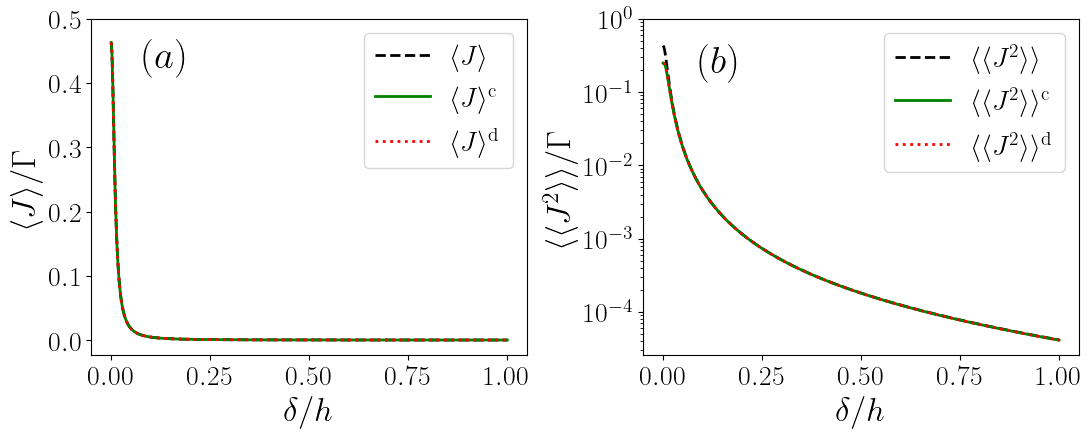

In [33]:
#Plot <J>, <<J^2>> vs delta
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
l0 = ax[0].plot(delta/eps, I_avg/Gamma,linewidth=2.0, color='black',linestyle='--',label=r'$\langle J \rangle$') 

l0 = ax[0].plot(delta/eps, IJ_2/Gamma, linewidth=2.0, color='g',linestyle='-',label=r'$\langle J \rangle^{\rm c}$') #^{\rm N}

l0 = ax[0].plot(delta/eps, IJ_d/Gamma, linewidth=2.0, color='r',linestyle=':',label=r'$\langle J \rangle^{\rm d}$') 

l1 = ax[1].plot(delta/eps, I_I/Gamma,linewidth=2.0, color='black',linestyle='--', label=r'$\langle \langle J^2 \rangle \rangle$') 

l2 = ax[1].plot(delta/eps, D2/Gamma,linewidth=2.0, color='g',linestyle='-', label=r'$\langle \langle J^2 \rangle \rangle^{\rm c} $') 

l2 = ax[1].plot(delta/eps, Dd/Gamma,linewidth=2.0, color='r',linestyle=':', label=r'$\langle \langle J^2 \rangle \rangle^{\rm d} $')

ax[0].text(0.2, 0.44, r"$(a)$",{'color': 'black', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');
ax[1].text(0.2, 0.25, r"$(b)$",{'color': 'black', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');


for a in ax.flat:
    a.set(xlabel=r'$\delta/ h$');
    a.legend(fontsize=20); #loc='lower right', 
    a.tick_params(labelsize=20);
    a.xaxis.label.set_size(24);
    a.yaxis.label.set_size(24);
    a.set_yticks(np.arange(0, 0.51, 0.1))
ax[0].set(ylabel=r'$\langle J \rangle/\Gamma$');
ax[1].set(ylabel=r'$\langle \langle J^2 \rangle \rangle/\Gamma$');
ax[1].set_yscale('log');
ax[1].set_ylim(top=1e0)
plt.tight_layout(pad=.7, w_pad=.7, h_pad=.3);
# fig.savefig('/Users/iliakhomchenko/Desktop/Postdoc/Non-Markovianity/Code/GitHub_V2/current_fluctuations_over_delta.pdf', format='pdf')